# Demand Model: Predicting Rideshare Trips per Area and Hour

Goal: predict how many rideshare trips start in each community area in each hour (issue #15), and check whether a machine-learning model beats simple baselines.

Data: the community area x hour feature table (`data/features/area_hour`), 2023 onward, with hours that had no trips filled in as 0. The model is trained by `src/models/demand_gbt.py`; this notebook reads its results from `results/model/`.

- **Features:** area, hour, day of week, month, weekend, holiday, daily weather (high and low temperature, rain, snow), and trips in the same area and hour 1 day, 7 days and an average of the last 4 weeks earlier. Trip averages (distance, fare) and same-day CTA ridership are left out because they are only known after the hour is over.
- **Split by time:** train Feb 2023 – Jun 2025, test Jul 2025 onward. A random split would let the model see the future.
- **Models:** two baselines (same hour last week; average of the last 4 weeks) and gradient-boosted trees (Spark MLlib `GBTRegressor`, 50 trees, depth 6).
- **Evaluation:** RMSE, MAE and R² on the test period.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RES = ROOT / "results" / "model"
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

metrics = pd.read_csv(RES / "metrics.csv")
imp = pd.read_csv(RES / "feature_importance.csv")
sample = pd.read_csv(RES / "sample_two_weeks.csv", parse_dates=["date"])
errors = pd.read_csv(RES / "area_errors.csv")
names = pd.read_csv(ROOT / "results" / "cta_access_by_area.csv").set_index("area")["name"].replace({"Ohare": "O'Hare"})
print(f"train rows: {metrics.train_rows[0]:,}   test rows: {metrics.test_rows[0]:,}")
metrics[["model", "rmse", "mae", "r2"]].round(3)

train rows: 1,628,088   test rows: 789,096


,model,rmse,mae,r2
0,Baseline: same hour last week,74.363,22.490,0.921
1,Baseline: average of last 4 weeks,60.476,19.015,0.948
2,Gradient-boosted trees,53.597,18.026,0.959


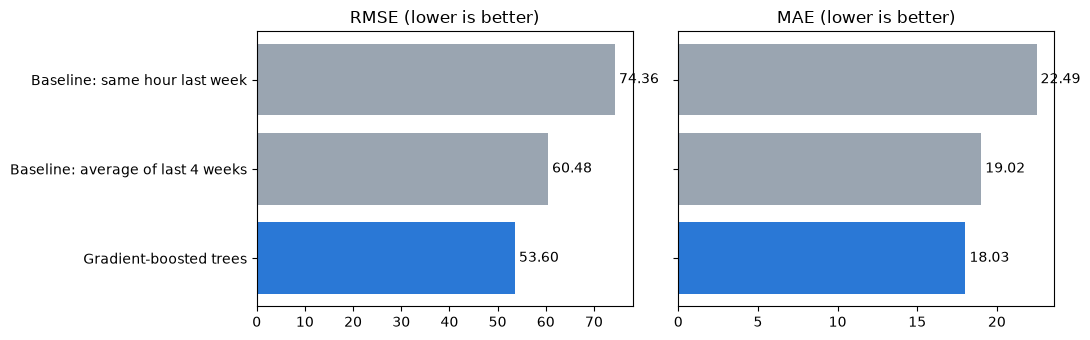

GBT vs 4-week average: RMSE 11.4% lower, MAE 5.2% lower


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
colors = ["#9aa5b1", "#9aa5b1", "#2a78d6"]
for ax, col, title in zip(axes, ["rmse", "mae"], ["RMSE (lower is better)", "MAE (lower is better)"]):
    ax.barh(metrics["model"], metrics[col], color=colors)
    ax.set_title(title)
    ax.invert_yaxis()
    for i, v in enumerate(metrics[col]):
        ax.text(v, i, f" {v:.2f}", va="center")
axes[1].set_yticklabels([])
plt.tight_layout()
plt.savefig(FIGS / "model_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

best, base = metrics.iloc[2], metrics.iloc[1]
print(f"GBT vs 4-week average: RMSE {100 * (1 - best.rmse / base.rmse):.1f}% lower, MAE {100 * (1 - best.mae / base.mae):.1f}% lower")

Gradient-boosted trees are the best model on the test period (Jul 2025 – Aug 2026, 789,096 area-hours): RMSE 53.60, MAE 18.03 and R² 0.959, compared with 60.48, 19.02 and 0.948 for the 4-week average and 74.36, 22.49 and 0.921 for "same hour last week". That is 11.4% lower RMSE and 5.2% lower MAE than the stronger baseline. The improvement is moderate: rideshare demand is so regular that a 4-week average already explains about 95% of the variation, and the bigger drop in RMSE than in MAE means the model mainly reduces the large misses at busy hours rather than the typical small errors.

## Which features matter

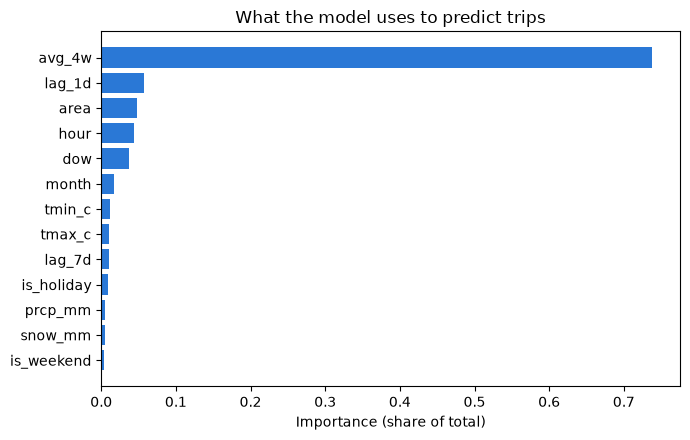

,feature,importance
0,avg_4w,0.7383
1,lag_1d,0.0579
2,area,0.0483
3,hour,0.0442
4,dow,0.0374
5,month,0.0175
6,tmin_c,0.0116
7,tmax_c,0.0110
8,lag_7d,0.0103
9,is_holiday,0.0093


In [3]:
top = imp.sort_values("importance")
plt.figure(figsize=(7, 4.5))
plt.barh(top["feature"], top["importance"], color="#2a78d6")
plt.xlabel("Importance (share of total)")
plt.title("What the model uses to predict trips")
plt.tight_layout()
plt.savefig(FIGS / "model_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
imp.round(4)

The 4-week average for the same area and hour dominates (0.74 of total importance), followed by trips at the same hour the day before (0.06), the area (0.05), the hour (0.04) and the day of week (0.04). All four weather features together add up to only 0.03, and holidays 0.01. Rideshare demand is mostly habit: where and when people rode in recent weeks predicts the next day far better than temperature, rain or snow.

## Predicted vs actual for two weeks

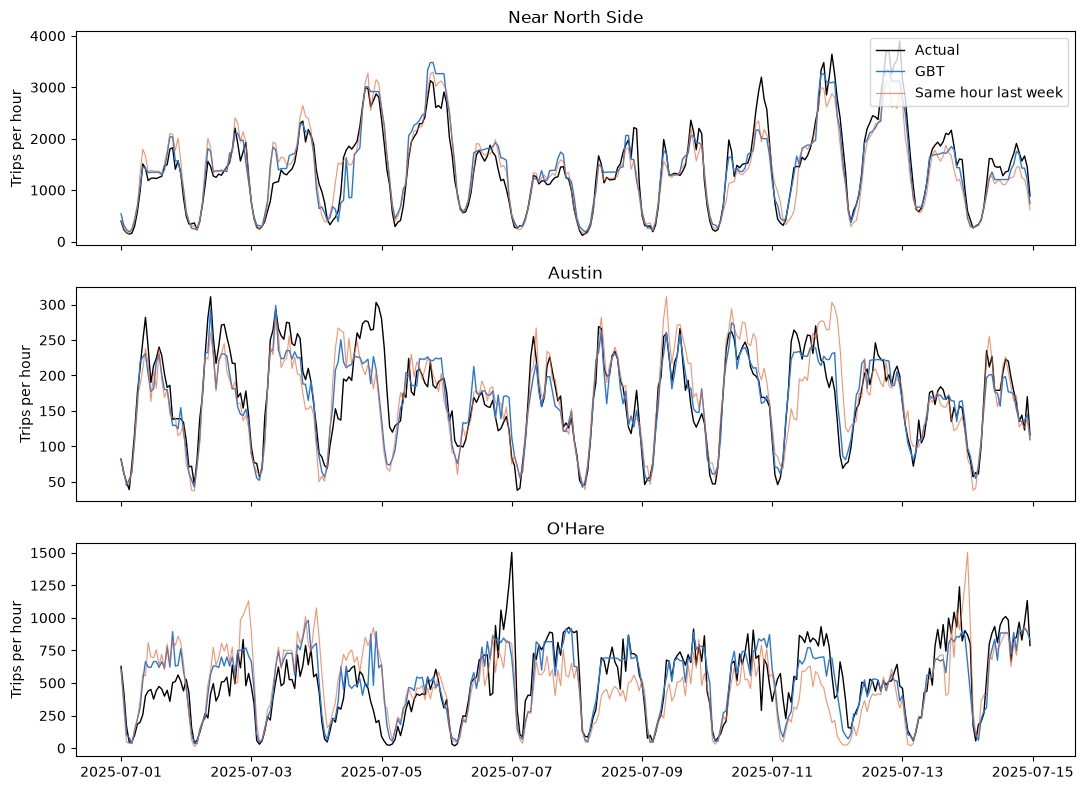

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, (area, g) in zip(axes, sample.groupby("area")):
    t = g["date"] + pd.to_timedelta(g["hour"], unit="h")
    ax.plot(t, g["trips"], color="black", lw=1, label="Actual")
    ax.plot(t, g["pred_gbt"], color="#2a78d6", lw=1, label="GBT")
    ax.plot(t, g["lag_7d"], color="#eb6834", lw=0.8, alpha=0.7, label="Same hour last week")
    ax.set_title(names.get(area, area))
    ax.set_ylabel("Trips per hour")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGS / "model_two_weeks.png", dpi=150, bbox_inches="tight")
plt.show()

The model follows the daily cycle closely in all three areas, including the evening peaks in the Near North Side and the night-time lows. It misses unusual hours: it underestimates the highest evening peaks in the Near North Side, the July 4 evening in Austin, and the spike at O'Hare on the evening of Sunday July 6 (about 1,500 trips against a prediction of about 850), when people flew back after the holiday weekend. It does better than "same hour last week" one week after the holiday (July 11–12), because it does not copy the holiday pattern into a normal week.

## Error by area

In [5]:
errors["name"] = errors["area"].map(names)
errors["mae_pct"] = 100 * errors["mae"] / errors["actual"].where(errors["actual"] > 0)
errors.sort_values("actual", ascending=False)[["area", "name", "actual", "predicted", "mae", "mae_pct"]].round(2).head(15)

,area,name,actual,predicted,mae,mae_pct
7,8,Near North Side,1397.04,1416.64,164.88,11.80
27,28,Near West Side,801.74,810.38,97.74,12.19
31,32,Loop,765.82,775.42,97.70,12.76
5,6,Lake View,586.66,584.62,95.87,16.34
75,76,O'Hare,573.37,569.01,107.58,18.76
23,24,West Town,453.38,458.99,59.85,13.20
6,7,Lincoln Park,448.12,451.46,62.45,13.94
21,22,Logan Square,287.42,288.39,36.22,12.60
40,41,Hyde Park,205.14,207.27,32.79,15.99
32,33,Near South Side,202.63,200.57,49.09,24.22


For the busiest areas the typical error is about 12–13% of the average trips per hour (Near North Side 11.8%, Near West Side 12.2%, Loop 12.8%), and the average prediction is close to the average actual value (1,417 vs 1,397 trips per hour in the Near North Side), so the model is not biased up or down. Errors are larger where travel depends on flights and events: O'Hare 18.8%, Garfield Ridge (Midway) 21.6% and the Near South Side (McCormick Place, Soldier Field) 24.2%.
## What this means for the project

- The model predicts next-day demand per area and hour with a typical error of about 12–19% of average trips in busy areas, and beats both baselines, so it can show when and where rideshare demand is high.
- Limits: it needs the last 4 weeks and the previous day of trips, so it predicts one day ahead, not months ahead; it cannot see events or flight schedules, so it misses holiday and event spikes; and weather adds very little.
- Harsh will use the predicted demand per area and hour (results/model/area_hour_profile.csv) for the hourly demand chart in the dashboard, so a planner can see which hours a transit-gap area needs service most.